# M2: Baseline Reproduction
**Anchor paper:** Yang et al., *Quantifying and Improving the Robustness of Retrieval-Augmented Language Models Against Spurious Features in Grounding Data*, ACL 2026 ([arXiv 2503.05587](https://arxiv.org/abs/2503.05587), [code](https://github.com/maybenotime/RAG-SpuriousFeatures)).

**What this notebook reproduces:** the *Robustness Rate (RR)* of **Llama-3.1-8B-Instruct** on the authors' released **SIG_Wiki** benchmark (`test_data/SIG_benchmark.json`, 16 perturbations x 100 pairs), i.e. the "Llama3.1-8B (Wiki)" row of **Table 6**.

| What | Paper | This notebook |
|---|---|---|
| Data | SIG_Wiki, 1,600 instance pairs | same file from the authors' repo |
| Model | Llama-3.1-8B-Instruct (bf16, vLLM, A100) | same weights, **4-bit NF4** on a free T4 |
| Prompt | instruction from Fig. 11 | authors' code, unchanged |
| Decoding | temperature 0.1 | greedy (default) or temperature 0.1 with seeds |
| Metric | RR / WR / LR, string match | authors' normalisation code |

**Runtime (Kaggle):** Settings → Accelerator → **GPU T4 x2**, Internet → **On**. Add your Hugging Face token under Add-ons → Secrets with the label `HF_TOKEN`. A full run takes roughly 30–60 minutes.

**Before you start:** request access to [meta-llama/Llama-3.1-8B-Instruct](https://huggingface.co/meta-llama/Llama-3.1-8B-Instruct) on Hugging Face and create a *read* token. If access has not arrived yet, set `MODEL_ID` to `mistralai/Mistral-7B-Instruct-v0.3` (access is granted instantly) and change `SELF_SUBSET` accordingly.

In [1]:
# 1. Install and get the authors' code + data
!pip -q install -U "transformers>=4.45" accelerate bitsandbytes regex pandas matplotlib
!git clone -q https://github.com/maybenotime/RAG-SpuriousFeatures.git || echo "repo already cloned"
!ls RAG-SpuriousFeatures/test_data

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
ydata-profiling 4.18.4 requires matplotlib<=3.10,>=3.5, but you have matplotlib 3.11.2 which is incompatible.
ydata-profiling 4.18.4 requires pandas!=1.4.0,<3.0,>1.5, but you have pandas 3.1.0 which is incompatible.
google-colab 1.0.0 requires jupyter-server==2.20.0, but you have jupyter-server 2.12.5 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
cudf-cu12 26.2.1 requires pandas<2

In [2]:
# 2. Configuration: change ONE thing at a time and note it in your report
MODEL_ID       = "meta-llama/Llama-3.1-8B-Instruct"   # or "mistralai/Mistral-7B-Instruct-v0.3"
SELF_SUBSET    = "self_preference_llama3_8b"          # use "self_preference_mistral_7b" for Mistral
LOAD_IN_4BIT   = True     # needed on a 16 GB T4 for 7-8B models
DO_SAMPLE      = False    # False = greedy (deterministic). True = temperature 0.1 like the paper
TEMPERATURE    = 0.1
TOP_P          = 0.9
SEEDS          = [0]      # with DO_SAMPLE=True try [0, 1, 2] to measure run-to-run variance
MAX_NEW_TOKENS = 64       # the instruction asks for <= 5 tokens; 64 leaves room
BATCH_SIZE     = 8        # lower to 4 if you get CUDA out-of-memory
DRY_RUN        = False    # True = no model, fake answers; only to test the pipeline quickly

# Where generations are cached so a disconnect does not lose work.
# On Kaggle, /kaggle/working is kept as the notebook's Output after "Save Version".
import os
OUT_DIR = "/kaggle/working/rag_m2" if os.path.exists("/kaggle/working") else "/content/rag_m2"

# Reported in the paper, Table 6, row "Llama3.1-8B (Wiki)", RR in %
REPORTED_RR = {"style": 10.0, "source": 15.5, "logic": 20.0, "format": 24.0, "meta": 94.0}

In [3]:
# 3. Load SIG_Wiki and look at it
import json, os, sys, random
from collections import Counter
import pandas as pd

REPO = "RAG-SpuriousFeatures"
sys.path.insert(0, REPO)
os.makedirs(OUT_DIR, exist_ok=True)

with open(f"{REPO}/test_data/SIG_benchmark.json") as f:
    SIG = json.load(f)

# The Source category holds a self-paraphrase for BOTH paper models; keep the one written by the model we evaluate.
OTHER_SELF = {"self_preference_llama3_8b", "self_preference_mistral_7b"} - {SELF_SUBSET}
inventory = [
    {"type": t, "perturbation": s, "pairs": len(v), "used": s not in OTHER_SELF}
    for t, subs in SIG.items() for s, v in subs.items()
]
inv = pd.DataFrame(inventory)
print("Total pairs used:", inv[inv.used].pairs.sum())
inv

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Total pairs used: 1500


,type,perturbation,pairs,used
0,format,format_preference_html,100,True
1,format,format_preference_json,100,True
2,format,format_preference_markdown,100,True
3,format,format_preference_yaml,100,True
4,style,simple_preference_llm,100,True
5,style,complex_preference_llm,100,True
6,logic,logic_preference_reverse,100,True
7,logic,logic_preference_random,100,True
8,logic,logic_preference_llm,100,True
9,source,source_preference_llm,100,True


In [4]:
# 4. Prompts: copied from the authors' evaluation script (construct_QA_prompts_for_qwen)
INSTRUCTION = ("You are given a question and you MUST respond by EXTRACTING the answer (max 5 tokens) "
               "from the provided document. If the document does not contain the answer, respond with NO-RES. ")

def build_prompt(question, doc, tokenizer=None):
    user = f"{INSTRUCTION}\nDocuments:\n{doc}\nQuestion: {question}"
    if tokenizer is None:          # dry run
        return user
    return tokenizer.apply_chat_template([{"role": "user", "content": user}],
                                         tokenize=False, add_generation_prompt=True)

def original_and_perturbed_docs(ptype, item):
    # Same rules as the authors' script: meta uses the HTML page as the original,
    # format/meta perturbed docs already contain the title, others get "title + text".
    original = item["html_text"] if ptype == "meta" else f'{item["title"]} {item["text"]}'
    perturbed = item["perturbed_doc"] if ptype in ("meta", "format") else f'{item["title"]} {item["perturbed_doc"]}'
    return original, perturbed

ex = SIG["format"]["format_preference_json"][0]
o, p = original_and_perturbed_docs("format", ex)
print("QUESTION:", ex["question"], "| GOLD:", ex["answers"][:3])
print("\n--- ORIGINAL ---\n", o[:400])
print("\n--- PERTURBED (JSON) ---\n", p[:400])

QUESTION: who was the spanish civil war fought between | GOLD: ['Republicans', 'Nationalists']

--- ORIGINAL ---
 Spanish Civil War in other countries. French novelist André Malraux was a strong supporter of the republican cause; he tried to organise a volunteer air force (Escadrile Espana) on the republican side but as a practical organiser and squadron leader he was somewhat idealistic and inefficient. The Regular Spanish Air force commander Andrés García La Calle was openly critical of Malraux's military e

--- PERTURBED (JSON) ---
 {"title": "Spanish Civil War", "text": "in other countries. French novelist Andr\u00e9 Malraux was a strong supporter of the republican cause; he tried to organise a volunteer air force (Escadrile Espana) on the republican side but as a practical organiser and squadron leader he was somewhat idealistic and inefficient. The Regular Spanish Air force commander Andr\u00e9s Garc\u00eda La Calle was op


In [5]:
# 5. Load the model (skipped in DRY_RUN)
tokenizer = model = None
if not DRY_RUN:
    import torch
    from huggingface_hub import login
    try:                                   # Kaggle: token stored in Add-ons -> Secrets as HF_TOKEN
        from kaggle_secrets import UserSecretsClient
        login(token=UserSecretsClient().get_secret("HF_TOKEN"))
    except Exception:
        login()                            # Colab / local: paste the token when asked
    from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
    tokenizer.padding_side = "left"              # required for batched generation
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    quant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                               bnb_4bit_compute_dtype=torch.float16) if LOAD_IN_4BIT else None
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID, device_map="auto", quantization_config=quant,
        torch_dtype=torch.float16)
    model.eval()
    print("Loaded", MODEL_ID, "| GPU:", torch.cuda.get_device_name(0))

config.json:   0%|          | 0.00/855 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/55.4k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/184 [00:00<?, ?B/s]

Loaded meta-llama/Llama-3.1-8B-Instruct | GPU: Tesla T4


In [6]:
# 6. Generate answers for every (original, perturbed) pair, with a resumable cache
import time
from tqdm.auto import tqdm

def generate(prompts, seed):
    if DRY_RUN:   # fake reader: answers correctly ~80% of the time
        out = []
        for p in prompts:
            rng = random.Random(f"{seed}|{p}")
            out.append(rng.choice(["NO-RES", "unknown"]) if rng.random() < 0.2 else "__GOLD__")
        return out
    torch.manual_seed(seed)
    enc = tokenizer(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
    with torch.no_grad():
        out = model.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=DO_SAMPLE,
                             temperature=TEMPERATURE if DO_SAMPLE else None,
                             top_p=TOP_P if DO_SAMPLE else None,
                             pad_token_id=tokenizer.pad_token_id)
    new_tokens = out[:, enc["input_ids"].shape[1]:]
    return [t.strip() for t in tokenizer.batch_decode(new_tokens, skip_special_tokens=True)]

def run_tag(seed):
    m = MODEL_ID.split("/")[-1]
    mode = f"sample{TEMPERATURE}" if DO_SAMPLE else "greedy"
    return f"{m}_{'4bit' if LOAD_IN_4BIT else 'fp16'}_{mode}_seed{seed}{'_DRY' if DRY_RUN else ''}"

def run_all(seed):
    path = f"{OUT_DIR}/generations_{run_tag(seed)}.jsonl"
    done = {}
    if os.path.exists(path):
        for line in open(path):
            r = json.loads(line); done[(r["perturbation"], r["idx"])] = r
    jobs = []
    for ptype, subs in SIG.items():
        for sub, items in subs.items():
            if sub in OTHER_SELF:
                continue
            for i, item in enumerate(items):
                if (sub, i) not in done:
                    o, p = original_and_perturbed_docs(ptype, item)
                    jobs.append((ptype, sub, i, item, build_prompt(item["question"], o, tokenizer),
                                 build_prompt(item["question"], p, tokenizer)))
    print(f"{run_tag(seed)}: {len(done)} cached, {len(jobs)} to run")
    # Sort by length so batches have similar padding -> much faster
    jobs.sort(key=lambda j: len(j[4]) + len(j[5]))
    t0 = time.time()
    with open(path, "a") as f:
        for b in tqdm(range(0, len(jobs), BATCH_SIZE)):
            batch = jobs[b:b + BATCH_SIZE]
            outs = generate([j[4] for j in batch] + [j[5] for j in batch], seed)
            n = len(batch)
            for j, o_ans, p_ans in zip(batch, outs[:n], outs[n:]):
                ptype, sub, i, item = j[:4]
                if DRY_RUN:
                    o_ans = item["answers"][0] if o_ans == "__GOLD__" else o_ans
                    p_ans = item["answers"][0] if p_ans == "__GOLD__" else p_ans
                rec = {"type": ptype, "perturbation": sub, "idx": i, "question": item["question"],
                       "answers": item["answers"], "org_result": o_ans, "perturbed_result": p_ans}
                done[(sub, i)] = rec
                f.write(json.dumps(rec) + "\n")
    print(f"done in {(time.time() - t0) / 60:.1f} min")
    return list(done.values())

runs = {seed: run_all(seed) for seed in SEEDS}

Llama-3.1-8B-Instruct_4bit_greedy_seed0: 0 cached, 1500 to run


  0%|          | 0/188 [00:00<?, ?it/s]

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


done in 30.3 min


In [7]:
# 7. Score exactly like the paper: normalised gold answer contained in the prediction
from normalize_answers import normalize_answer   # authors' file (SQuAD-style normalisation)

def is_correct(prediction, golds):
    p = normalize_answer(prediction)
    return any(normalize_answer(g) in p for g in golds)

def score(records):
    rows = []
    for r in records:
        y, y_hat = is_correct(r["org_result"], r["answers"]), is_correct(r["perturbed_result"], r["answers"])
        c = int(y) - int(y_hat)            # paper: C = Y(y) - Y(y_hat)
        rows.append({**r, "org_correct": y, "pert_correct": y_hat, "C": c})
    return pd.DataFrame(rows)

def summarise(df):
    per_sub = (df.groupby(["type", "perturbation"])
                 .agg(n=("C", "size"),
                      RR=("C", lambda c: 100 * (c == 0).mean()),
                      WR=("C", lambda c: 100 * (c == -1).mean()),
                      LR=("C", lambda c: 100 * (c == 1).mean()),
                      acc_original=("org_correct", lambda x: 100 * x.mean()),
                      acc_perturbed=("pert_correct", lambda x: 100 * x.mean()))
                 .round(1).reset_index())
    # Paper: category RR = average of its perturbations' RR
    per_type = per_sub.groupby("type")[["RR", "WR", "LR"]].mean().round(1)
    return per_sub, per_type

scored = {seed: score(recs) for seed, recs in runs.items()}
per_sub, per_type = summarise(scored[SEEDS[0]])
per_sub

,type,perturbation,n,RR,WR,LR,acc_original,acc_perturbed
0,format,format_preference_html,100,47.0,6.0,47.0,69.0,28.0
1,format,format_preference_json,100,65.0,12.0,23.0,63.0,52.0
2,format,format_preference_markdown,100,80.0,17.0,3.0,51.0,65.0
3,format,format_preference_yaml,100,66.0,18.0,16.0,54.0,56.0
4,logic,logic_preference_llm,100,72.0,12.0,16.0,60.0,56.0
5,logic,logic_preference_random,100,66.0,15.0,19.0,57.0,53.0
6,logic,logic_preference_reverse,100,68.0,13.0,19.0,57.0,51.0
7,meta,metadata_datasource_twitter,100,89.0,5.0,6.0,29.0,28.0
8,meta,metadata_datasource_wiki,100,88.0,12.0,0.0,28.0,40.0
9,meta,metadata_timestamp_post,100,89.0,4.0,7.0,34.0,31.0


In [8]:
# 8. Reproduced vs reported (Table 6) and the reproduction gap
order = ["style", "source", "logic", "format", "meta"]
cmp = pd.DataFrame({
    "reported_RR": pd.Series(REPORTED_RR),
    **{f"reproduced_RR_seed{s}": summarise(scored[s])[1]["RR"] for s in SEEDS},
}).loc[order]
rep_cols = [c for c in cmp.columns if c.startswith("reproduced")]
cmp["reproduced_mean"] = cmp[rep_cols].mean(axis=1).round(1)
if len(SEEDS) > 1:
    cmp["reproduced_std"] = cmp[rep_cols].std(axis=1).round(1)
cmp["gap (repro - paper)"] = (cmp["reproduced_mean"] - cmp["reported_RR"]).round(1)
cmp.to_csv(f"{OUT_DIR}/table6_comparison_{run_tag(SEEDS[0])}.csv")
per_sub.to_csv(f"{OUT_DIR}/per_perturbation_{run_tag(SEEDS[0])}.csv", index=False)
cmp

,reported_RR,reproduced_RR_seed0,reproduced_mean,gap (repro - paper)
style,10.0,56.5,56.5,46.5
source,15.5,49.0,49.0,33.5
logic,20.0,68.7,68.7,48.7
format,24.0,64.5,64.5,40.5
meta,94.0,90.0,90.0,-4.0


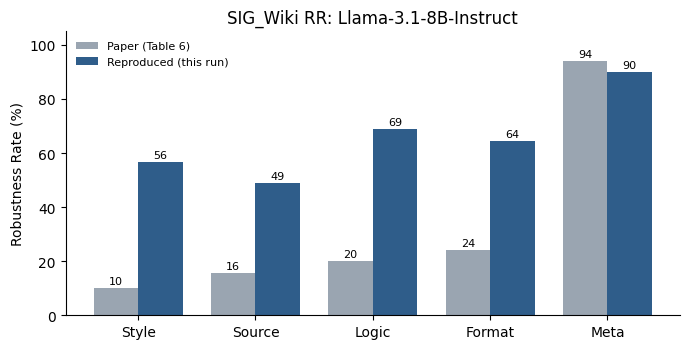

In [9]:
# 9. Figure for the report
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(order)); w = 0.38
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(x - w/2, cmp["reported_RR"], w, label="Paper (Table 6)", color="#9aa5b1")
ax.bar(x + w/2, cmp["reproduced_mean"], w, label="Reproduced (this run)", color="#2f5d8a",
       yerr=cmp["reproduced_std"] if "reproduced_std" in cmp else None, capsize=3)
err = cmp["reproduced_std"].fillna(0) if "reproduced_std" in cmp else pd.Series(0, index=cmp.index)
for i, (a, b, e) in enumerate(zip(cmp["reported_RR"], cmp["reproduced_mean"], err)):
    ax.text(i - w/2, a + 1.5, f"{a:.0f}", ha="center", fontsize=8)
    ax.text(i + w/2, b + e + 1.5, f"{b:.0f}", ha="center", fontsize=8)
ax.set_xticks(x, [o.capitalize() for o in order]); ax.set_ylim(0, 105)
ax.set_ylabel("Robustness Rate (%)"); ax.set_title(f"SIG_Wiki RR: {MODEL_ID.split('/')[-1]}")
ax.legend(frameon=False, fontsize=8); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/rr_comparison.png", dpi=200); plt.show()

## 10. Gap analysis helpers
Use these numbers in the *reproduction gap* section of the report. Do not hide the gap; explain it.

In [10]:
df = scored[SEEDS[0]]

# (a) Selection effect: SIG_Wiki keeps only pairs where the paper's runs were NOT robust.
#     If our run flips far less often, the "hard" cases were partly a product of one noisy run.
print("Share of pairs where correctness flipped (100 - RR):", round(100 - 100 * (df.C == 0).mean(), 1), "%")

# (b) Accuracy before vs after perturbation per category
print(df.groupby("type")[["org_correct", "pert_correct"]].mean().mul(100).round(1))

# (c) Does the model follow the format? Long or NO-RES answers change string-match scores
df["org_len"] = df.org_result.str.split().str.len()
print("Median answer length (words):", df.org_len.median(),
      "| NO-RES on original:", round(100 * df.org_result.str.contains("NO-RES").mean(), 1), "%")

# (d) Run-to-run variance (only when SEEDS has >1 entry and DO_SAMPLE=True)
if len(SEEDS) > 1:
    a, b = scored[SEEDS[0]], scored[SEEDS[1]]
    same = (a.set_index(["perturbation", "idx"]).org_correct ==
            b.set_index(["perturbation", "idx"]).org_correct).mean()
    print(f"Original-prompt correctness identical across two seeds: {100*same:.1f}%  "
          "-> the noise floor with NO perturbation at all")

Share of pairs where correctness flipped (100 - RR): 31.0 %
        org_correct  pert_correct
type                             
format         59.2          50.2
logic          58.0          53.3
meta           32.8          33.2
source         51.0          55.0
style          52.5          52.0
Median answer length (words): 3.0 | NO-RES on original: 28.1 %


In [11]:
# (e) Examples where the perturbation broke a correct answer (keep 5 for the report)
lose = df[df.C == 1].sample(min(5, (df.C == 1).sum()), random_state=0)
for _, r in lose.iterrows():
    print(f"[{r.perturbation}] Q: {r.question}\n  gold: {r.answers[:3]}\n"
          f"  original -> {r.org_result!r}\n  perturbed -> {r.perturbed_result!r}\n")

[logic_preference_reverse] Q: who was running as vice president in 1984
  gold: ['Ferraro', 'Vice President George H.W. Bush', 'Congresswoman Ferraro']
  original -> 'George H. W. Bush'
  perturbed -> 'Reagan'

[format_preference_json] Q: where can i get a state issued id
  gold: ["each state 's DMV", 'DMV']
  original -> 'DMV'
  perturbed -> 'NO-RES'

[self_preference_llama3_8b] Q: what was the purpose of the mall of america
  gold: ['shopping']
  original -> 'The site of the Metropolitan Stadium became the Mall of America, which housed more than 800 stores, making it the largest shopping center in the United States.'
  perturbed -> 'demolished to make way for the sprawling Mall of America, boasting over 800 stores'

[logic_preference_llm] Q: when did canada get rid of the death penalty
  gold: ['1998', 'July 14 , 1976', '1976']
  original -> '1998'
  perturbed -> 'when did canada get rid of the death penalty \nanswer: June 30, 1987'

[logic_preference_reverse] Q: the era of the great

## 11. What to write in the M2 report
1. **Setup:** dataset (SIG_Wiki, 1,600 pairs, 1,500 used: one self-paraphrase subset per model), preprocessing (none beyond the authors' prompt construction), model and precision, decoding, batch size, hardware, run time.
2. **Original vs reproduced:** the table from step 8 and the figure from step 9.
3. **Gap analysis,** one factor at a time: quantisation (4-bit vs bf16), decoding (greedy vs temperature 0.1), chat template (`add_generation_prompt=True`), max tokens, **selection effect** of SIG_Wiki, seed variance (step 10d), string-match vs LLM-as-judge (paper used Llama-3.1-70B as judge in a robustness check; not reproduced here).
4. **What could not be reproduced and why:** building SURE_Wiki (100k instances, Llama-3.1-70B perturbations), SFT/DPO training (8 x A100).